In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# 1. Importing Libraries and Setting Up the Environment

This section imports the essential Python libraries and machine learning utilities required for the Titanic Survival Prediction project.

### Libraries and Their Purpose

- **NumPy:** Supports numerical computations and array operations.
- **Pandas:** Handles data manipulation, processing, and analysis.
- **Matplotlib:** Creates visualizations for exploring the dataset.
- **Seaborn:** Provides statistical data visualization.
- **Scikit-learn:** Supplies machine learning utilities for:
  - Splitting datasets into training and validation sets.
  - Encoding categorical variables using Label Encoding.
  - Evaluating model performance using accuracy, classification reports, and confusion matrices.
  - Performing cross-validation to assess model generalization.

### Visualization and Display Configuration

Seaborn is configured with the `whitegrid` theme to improve visualization readability, while Pandas is configured to display all columns when inspecting DataFrames.

These configurations establish a consistent analytical environment for the subsequent exploratory data analysis, preprocessing, model development, and evaluation stages.

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")

pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

## 2. Loading the Datasets

In this section, we load the Titanic competition datasets using Pandas.

Three CSV files are imported:
- **train.csv:** Contains passenger information and survival labels used to train the machine learning model.
- **test.csv:** Contains passenger information without survival labels, used to generate final predictions.
- **gender_submission.csv:** Provides a sample submission file for reference.

The datasets are loaded from Kaggle's competition input directory, and their dimensions are displayed to verify that they have been imported successfully.

This establishes the datasets required for exploratory data analysis, preprocessing, feature engineering, and model development.

In [ ]:
DATA_PATH = '/kaggle/input/competitions/titanic/'

train = pd.read_csv(DATA_PATH + 'train.csv')
test = pd.read_csv(DATA_PATH + 'test.csv')
gender_submission = pd.read_csv(DATA_PATH + 'gender_submission.csv')

print("Datasets loaded successfully!")

print("\nTraining dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)
print("Gender submission shape:", gender_submission.shape)

## 3. Exploring the Training Dataset

The `train.head()` command displays the first five rows of the training dataset. This provides an initial overview of the available features, column names, and data structure.

This step helps verify that the dataset has been loaded correctly and provides an understanding of the information available for exploratory data analysis and subsequent preprocessing.

In [ ]:
train.head()

## 4. Inspecting Dataset Structure and Data Types

The `train.info()` method provides a detailed overview of the training dataset, including the number of entries, column names, non-null values, and data types.

The additional commands examine the dataset dimensions, list all available columns, and display their respective data types.

This step is important for identifying missing values, understanding the structure of the dataset, and determining which features may require data cleaning or preprocessing before model development.

In [ ]:
train.info()

print("\nDataset dimensions:", train.shape)

print("\nDataset columns:")
print(train.columns.tolist())

print("\nData types:")
print(train.dtypes)

## 5. Identifying Missing Values

This step performs a missing-value analysis on the training dataset using `isnull().sum()` to calculate the number of missing entries in each column.

The missing-value percentages are also computed to determine the proportion of incomplete records relative to the total number of observations.

A summary DataFrame is created, filtered to include only columns containing missing values, and sorted in descending order based on their missing-value percentages.

This analysis helps identify data quality issues and informs the appropriate imputation or data-cleaning strategies during preprocessing.

In [ ]:
missing_values = train.isnull().sum()

missing_percentage = (missing_values / len(train)) * 100
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Percentage (%)', ascending=False)

display(missing_summary)

## 6. Generating Descriptive Statistics

The `describe()` method is used to generate descriptive statistics for the numerical features in the training dataset, including count, mean, standard deviation, minimum, maximum, and quartile values.

The second command, `describe(include=['object'])`, provides summary statistics for categorical features, including the number of unique values, most frequent category, and its frequency.

Together, these summaries provide insights into the distribution of numerical and categorical variables, helping identify potential outliers, understand feature characteristics, and guide subsequent exploratory data analysis and preprocessing decisions.

In [ ]:
display(train.describe())
display(train.describe(include=['object']))

## 8. Visualizing the Target Variable Distribution

This step further examines the distribution of the `Survived` target variable by calculating the number and percentage of passengers in each survival category.

The Seaborn `countplot()` function is used to generate a bar chart showing the number of passengers who survived (1) and those who did not survive (0).

The visualization provides a clear representation of the target class distribution, helping assess class imbalance and understand the prediction task before proceeding with feature analysis and model development.

In [ ]:
survival_counts = train['Survived'].value_counts()

print("Survival counts:")
print(survival_counts)

print("\nSurvival percentages:")
print(train['Survived'].value_counts(normalize=True) * 100)

plt.figure(figsize=(8, 5))

sns.countplot(data=train, x='Survived')

plt.title('Titanic Passenger Survival Distribution')
plt.xlabel('Survival (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

## 9. Analyzing Survival Rates by Gender

This step investigates the relationship between passenger gender and survival outcomes.

The `groupby('Sex')['Survived'].mean()` operation calculates the average survival rate for male and female passengers. Multiplying the results by 100 converts the rates into percentages.

A Seaborn `barplot()` is then used to visualize the survival rates across the two gender categories, with error bars disabled to display the calculated averages directly.

This analysis helps identify gender-based differences in survival outcomes and highlights the potential predictive importance of the `Sex` feature in the machine learning model.

In [ ]:
gender_survival = train.groupby('Sex')['Survived'].mean() * 100

print("Survival rate by gender:")
print(gender_survival)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x='Sex',
    y='Survived',
    errorbar=None
)

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate')

plt.show()

## 10. Analyzing Survival Rates by Passenger Class

This step examines the relationship between passenger class (`Pclass`) and survival outcomes to determine how socioeconomic class influenced survival rates.

The `groupby('Pclass')['Survived'].mean()` operation calculates the average survival rate for each passenger class. Multiplying by 100 converts the results into percentages.

A Seaborn `barplot()` is then used to visualize the survival rates across first, second, and third-class passengers, with error bars disabled to display the calculated averages directly.

This analysis helps identify differences in survival outcomes across passenger classes and determine whether `Pclass` is an important predictive feature for the classification model.

In [ ]:
class_survival = train.groupby('Pclass')['Survived'].mean() * 100

print("Survival rate by passenger class:")
print(class_survival)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x='Pclass',
    y='Survived',
    errorbar=None
)

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

plt.show()

## 11. Analyzing Survival Rates by Embarkation Port

This step investigates the relationship between passengers' embarkation ports and their survival outcomes.

The `groupby('Embarked')['Survived'].mean()` operation calculates the average survival rate for passengers boarding at each port. Multiplying the results by 100 converts the rates into percentages.

A Seaborn `barplot()` is used to visualize survival rates across the three embarkation ports:
- **C:** Cherbourg
- **Q:** Queenstown
- **S:** Southampton

Error bars are disabled to display the calculated average survival rates directly.

This analysis helps identify variations in survival outcomes based on embarkation location and assess whether the `Embarked` feature contributes useful predictive information to the machine learning model.

In [ ]:
embarked_survival = train.groupby('Embarked')['Survived'].mean() * 100

print("Survival rate by embarkation port:")
print(embarked_survival)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x='Embarked',
    y='Survived',
    errorbar=None
)

plt.title('Survival Rate by Embarkation Port')
plt.xlabel('Embarkation Port')
plt.ylabel('Survival Rate')

plt.show()

## 12. Analyzing Age Distribution by Survival Status

This step explores the distribution of passenger ages and examines how age relates to survival outcomes.

The Seaborn `histplot()` function generates an overlaid histogram of passenger ages, using the `Survived` variable to distinguish between survivors (1) and non-survivors (0).

The visualization uses 30 bins to group ages into intervals, while `kde=True` adds smooth density curves to highlight the underlying age distributions.

This analysis helps identify age-related survival patterns, compare the age distributions of survivors and non-survivors, and assess the potential predictive value of the `Age` feature for the classification model.

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=train,
    x='Age',
    hue='Survived',
    bins=30,
    kde=True,
    multiple='layer'
)

plt.title('Age Distribution by Survival Status')
plt.xlabel('Passenger Age')
plt.ylabel('Number of Passengers')

plt.show()

## 13. Feature Engineering: Family Size and Traveling Alone

This step introduces two additional features to capture family-related information that may influence passenger survival.

**1. FamilySize**

A new feature is created by adding the number of siblings/spouses (`SibSp`) and parents/children (`Parch`), plus one to account for the passenger:

`FamilySize = SibSp + Parch + 1`

**2. IsAlone**

A binary feature is introduced to identify passengers traveling alone. Passengers with a `FamilySize` of 1 are assigned a value of 1, while those traveling with family members receive 0.

The analysis then groups passengers by family size and calculates the corresponding survival percentages. A bar chart visualizes these results to highlight differences in survival outcomes across family sizes.

These engineered features provide additional information about family relationships and travel circumstances, potentially improving the predictive performance of the classification model.

In [ ]:
# Create FamilySize feature
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1

# Create IsAlone feature
train['IsAlone'] = (train['FamilySize'] == 1).astype(int)

# Analyze survival by family size
family_survival = train.groupby('FamilySize')['Survived'].mean() * 100

print("Survival Rate by Family Size:")
print(family_survival)

# Visualize survival by family size
plt.figure(figsize=(9, 5))

sns.barplot(
    x=family_survival.index,
    y=family_survival.values
)

plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Survival Rate (%)')
plt.show()


### 11. Feature Engineering and Dataset Preparation

In this stage, feature engineering is performed on both the training and testing datasets to create additional predictive variables and prepare the data for model development.

**Key Operations:**

1. **Load Test Dataset:** Loads the Titanic test dataset from the competition input directory.

2. **Create FamilySize Feature:** Calculates the total family size for each passenger by adding `SibSp` and `Parch`, plus one for the passenger.

3. **Create IsAlone Feature:** Introduces a binary feature to identify passengers travelling alone (`1`) or with family (`0`).

4. **Feature Selection:** Selects nine relevant features for model development:
   - `Pclass`
   - `Sex`
   - `Age`
   - `SibSp`
   - `Parch`
   - `Fare`
   - `Embarked`
   - `FamilySize`
   - `IsAlone`

5. **Separate Features and Target:** Defines `X` as the independent training features and `y` as the target variable (`Survived`). The testing features are stored in `X_test`.

6. **Inspect Dataset Structure:** Displays the dimensions of the training features, target variable, and testing features, alongside a preview of the selected training columns.

**Outcome:** Both datasets now contain the same nine selected features, with the target variable separated from the training data. They are ready for preprocessing and machine learning model training.

In [ ]:

# Load test dataset
test = pd.read_csv('/kaggle/input/competitions/titanic/test.csv')

# Create family features in test data
test['FamilySize'] = test['SibSp'] + test['Parch'] + 1
test['IsAlone'] = (test['FamilySize'] == 1).astype(int)

# Select useful features
features = [
    'Pclass',
    'Sex',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'Embarked',
    'FamilySize',
    'IsAlone'
]

# Separate features and target
X = train[features].copy()
y = train['Survived'].copy()

X_test = test[features].copy()

# Display dataset shapes
print("Training features:", X.shape)
print("Target:", y.shape)
print("Test features:", X_test.shape)

display(X.head())


### 12. Data Preprocessing and Feature Transformation

This stage applies preprocessing techniques to handle missing values and convert categorical variables into numerical representations suitable for machine learning algorithms.

**Key Operations:**

1. **Import Preprocessing Tools:** Imports `SimpleImputer`, `OneHotEncoder`, `ColumnTransformer`, and `Pipeline` from Scikit-learn.

2. **Identify Feature Types:**
   - Numerical features: `Pclass`, `Age`, `SibSp`, `Parch`, `Fare`, `FamilySize`, and `IsAlone`.
   - Categorical features: `Sex` and `Embarked`.

3. **Numerical Data Imputation:** Uses `SimpleImputer` with the median strategy to replace missing numerical values.

4. **Categorical Data Imputation:** Uses the most frequent strategy to fill missing categorical values.

5. **Categorical Encoding:** Applies `OneHotEncoder` to convert categorical variables into numerical features. The `handle_unknown='ignore'` parameter prevents errors when previously unseen categories appear in the test dataset.

6. **Combine Preprocessing Steps:** Uses `ColumnTransformer` to apply the appropriate transformations to numerical and categorical features within a single preprocessing framework.

7. **Transform Datasets:**
   - Fits the preprocessing pipeline on the training dataset (`X`) and transforms it into `X_processed`.
   - Applies the same fitted transformations to the test dataset (`X_test`) to produce `X_test_processed`.

**Outcome:** Both datasets are transformed into numerical feature representations, with missing values handled and categorical variables encoded consistently. The processed datasets are now ready for model training and prediction.

In [ ]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numerical_features = [
    'Pclass', 'Age', 'SibSp', 'Parch',
    'Fare', 'FamilySize', 'IsAlone'
]

categorical_features = ['Sex', 'Embarked']

# Numerical preprocessing
numerical_transformer = SimpleImputer(strategy='median')

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

# Transform training and test datasets
X_processed = preprocessor.fit_transform(X)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Processed training shape:", X_processed.shape)
print("Processed test shape:", X_test_processed.shape)

print("\nRemaining missing values:",
      pd.isna(X_processed).sum())


### 13. Splitting Data into Training and Validation Sets

This stage divides the preprocessed training dataset into separate training and validation subsets to evaluate model performance on unseen data.

**Key Operations:**

1. **Import Data Splitting Tool:** Uses Scikit-learn's `train_test_split` function to partition the dataset.

2. **Split the Dataset:** Divides the processed features (`X_processed`) and target variable (`y`) into:
   - **Training Set (80%):** Used to train the machine learning models.
   - **Validation Set (20%):** Used to assess model performance and evaluate its ability to generalize to unseen data.

3. **Reproducibility:** Sets `random_state=42` to ensure consistent results whenever the dataset is split.

4. **Stratified Sampling:** Uses `stratify=y` to preserve the original survival class distribution across both training and validation sets.

5. **Dataset Size Verification:** Displays the number of training and validation samples.

6. **Target Distribution Analysis:** Examines the percentage distribution of survived (1) and non-survived (0) passengers in both subsets to verify class balance.

**Outcome:** The dataset is successfully divided into training and validation subsets while maintaining a consistent target class distribution. The training data is ready for model fitting, while the validation data will be used for performance evaluation and model selection.

In [ ]:

from sklearn.model_selection import train_test_split

# Split data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_processed,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True) * 100)


### 14. Random Forest Model Training and Evaluation

This stage implements a Random Forest Classifier to predict passenger survival using the preprocessed training data and evaluates its predictive performance on the validation dataset.

**Key Operations:**

1. **Import Machine Learning Tools:** Imports `RandomForestClassifier` and evaluation metrics, including `accuracy_score`, `classification_report`, and `confusion_matrix`.

2. **Initialize Random Forest Model:** Configures the classifier with the following hyperparameters:
   - `n_estimators=200`: Builds 200 decision trees.
   - `max_depth=6`: Limits the maximum depth of each tree to control model complexity.
   - `min_samples_split=5`: Requires at least five samples to split an internal node.
   - `min_samples_leaf=2`: Requires at least two samples in each leaf node.
   - `random_state=42`: Ensures reproducibility.
   - `class_weight='balanced'`: Adjusts class weights to account for differences in survival class frequencies.

3. **Model Training:** Fits the Random Forest classifier using the training features (`X_train`) and corresponding target labels (`y_train`).

4. **Validation Predictions:** Uses the trained model to predict passenger survival on the validation dataset (`X_val`).

5. **Accuracy Evaluation:** Calculates and displays validation accuracy as both a decimal and percentage.

6. **Classification Report:** Evaluates the model using:
   - **Precision:** Measures the proportion of correct positive predictions.
   - **Recall:** Measures the proportion of actual positive cases correctly identified.
   - **F1-score:** Provides a balance between precision and recall.
   - **Support:** Shows the number of actual samples in each class.

7. **Confusion Matrix:** Examines correct and incorrect predictions across both survival classes, providing insight into the model's classification performance.

**Outcome:** The Random Forest model is successfully trained and evaluated using the validation dataset. The evaluation metrics provide a baseline for assessing predictive performance and guiding subsequent hyperparameter optimization.

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Initialize Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight='balanced'
)

# Train the model
rf_model.fit(X_train, y_train)

# Make validation predictions
y_pred = rf_model.predict(X_val)

# Evaluate model
accuracy = accuracy_score(y_val, y_pred)

print("Random Forest Model Evaluation")
print("--------------------------------")
print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))


### 15. Hyperparameter Optimization Using Grid Search Cross-Validation

This stage optimizes the Random Forest classifier by systematically testing different hyperparameter combinations to identify the configuration that delivers the best cross-validation performance.

**Key Operations:**

1. **Import GridSearchCV:** Uses Scikit-learn's `GridSearchCV` to perform an exhaustive search across predefined hyperparameter combinations.

2. **Define Hyperparameter Grid:** Specifies the following parameters for optimization:
   - `n_estimators`: [100, 200, 300] — Number of decision trees.
   - `max_depth`: [4, 6, 8, 10, None] — Maximum depth of each decision tree.
   - `min_samples_split`: [2, 5, 10] — Minimum number of samples required to split a node.
   - `min_samples_leaf`: [1, 2, 4] — Minimum number of samples required at a leaf node.

3. **Initialize Grid Search:** Configures `GridSearchCV` with:
   - Random Forest as the estimator.
   - Five-fold cross-validation (`cv=5`).
   - Accuracy as the evaluation metric (`scoring='accuracy'`).
   - Parallel processing (`n_jobs=-1`) to utilize available CPU resources.
   - Verbose output to monitor the search process.

4. **Hyperparameter Optimization:** Fits Grid Search on the training dataset (`X_train`, `y_train`) to evaluate different parameter combinations across five cross-validation folds.

5. **Identify Best Parameters:** Retrieves the optimal hyperparameter configuration using `best_params_`.

6. **Evaluate Cross-Validation Performance:** Reports the highest cross-validation accuracy using `best_score_`.

7. **Validate Tuned Model:** Extracts the best-performing estimator, generates predictions on the validation dataset, and calculates the resulting validation accuracy.

**Outcome:** Grid Search successfully identifies the best Random Forest hyperparameters based on five-fold cross-validation. The optimized model is subsequently evaluated against the validation dataset to assess its generalization performance and compare it with the initial Random Forest model.

In [ ]:

from sklearn.model_selection import GridSearchCV

# Define hyperparameter combinations
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize Grid Search
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Train and search for the best parameters
grid_search.fit(X_train, y_train)

# Display results
print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_ * 100, 2), "%")

# Evaluate the tuned model
best_model = grid_search.best_estimator_

tuned_predictions = best_model.predict(X_val)

tuned_accuracy = accuracy_score(y_val, tuned_predictions)

print("\nValidation Accuracy After Tuning:")
print(round(tuned_accuracy * 100, 2), "%")


### 16. Final Random Forest Model Training

This stage trains the final Random Forest classifier using the complete preprocessed training dataset to prepare it for generating predictions on the competition test dataset.

**Key Operations:**

1. **Initialize the Final Model:** Creates a new `RandomForestClassifier` using the selected configuration:
   - `n_estimators=200`: Uses 200 decision trees.
   - `max_depth=6`: Limits tree depth to control model complexity.
   - `min_samples_split=5`: Requires at least five samples to split an internal node.
   - `min_samples_leaf=2`: Requires at least two samples in each leaf node.
   - `random_state=42`: Ensures reproducibility.
   - `class_weight='balanced'`: Accounts for differences in class frequencies.

2. **Train on the Complete Dataset:** Fits the final model using `X_processed` and `y`, incorporating all 891 available training samples rather than only the training subset used during validation.

3. **Confirm Successful Training:** Displays a confirmation message once the model has been fitted successfully.

4. **Verify Training Dimensions:** Reports the total number of training samples and features used by the final model.

**Outcome:** The final Random Forest model is successfully trained on the complete training dataset, using 12 processed features. It is now ready to generate survival predictions for the 418 passengers in the competition test dataset.

In [ ]:

# Train final Random Forest model on all training data

final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight='balanced'
)

# Fit on the complete training dataset
final_model.fit(X_processed, y)

print("Final model trained successfully!")

print("Training samples:", X_processed.shape[0])
print("Features:", X_processed.shape[1])


### 17. Final Model Verification

This stage verifies that the final trained Random Forest model and the optimized Grid Search model are successfully defined and accessible within the current Python environment.

**Key Operations:**

1. **Check Final Model:** Uses `globals()` to confirm whether the `final_model` variable exists in the current notebook environment.
2. **Check Optimized Model:** Verifies whether the `best_model` variable, obtained from Grid Search optimization, is also available.
3. **Variable Verification:** Confirms that the required model objects are accessible before proceeding with test dataset predictions.

**Outcome:** Both model variables are checked to ensure the notebook has access to the trained final model and the hyperparameter-optimized model. The `final_model` is the model selected for generating the competition test predictions in the subsequent stage.

In [ ]:
print("final_model exists:", 'final_model' in globals())
print("best_model exists:", 'best_model' in globals())

## 15. Generate Predictions on the Test Dataset

After training the final Random Forest model on the complete training dataset, predictions are generated for all passengers in the test dataset.

The trained model uses the preprocessed test features (`X_test_processed`) to predict each passenger's survival status.

**Prediction Results:**
- Total predictions generated: 418
- Predicted not survived (0): 248 passengers
- Predicted survived (1): 170 passengers

The prediction distribution provides an overview of the model's classification results. These predictions will be used to construct the final Kaggle submission file.

In [ ]:
# Generate predictions using the final trained model
test_predictions = final_model.predict(X_test_processed)

print("Predictions generated successfully!")
print("Total predictions:", len(test_predictions))

print("\nPrediction distribution:")
print(pd.Series(test_predictions).value_counts())

## 15. Creating and Validating the Kaggle Submission

This section prepares the final predictions for submission to the Titanic - Machine Learning from Disaster competition.

The predicted survival outcomes are combined with the corresponding passenger IDs to create a submission DataFrame containing the two required columns: `PassengerId` and `Survived`.

The submission is then validated by:
- Displaying the first 10 predictions for inspection.
- Checking the submission dimensions to ensure all test passengers are included.
- Verifying that no missing values exist in the submission.
- Saving the final predictions as `submission.csv` in the Kaggle working directory.

This ensures that the submission file follows the competition's required format and is ready for evaluation.

In [ ]:
# Create Kaggle submission dataframe
submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': test_predictions
})

# Preview submission
display(submission.head(10))

# Validate submission
print("Submission shape:", submission.shape)
print("\nMissing values:")
print(submission.isnull().sum())

# Save submission file
submission.to_csv('/kaggle/working/submission.csv', index=False)

print("\nSubmission file saved successfully!")

 # 16.Titanic Model Improvement and Optimization

Having successfully developed and submitted our initial Random Forest model, the next phase focuses on improving predictive performance.

Our previous model achieved a public leaderboard accuracy of 0.76076. We will now explore more advanced machine learning techniques to improve its generalization ability and predictive accuracy.

The optimization process will involve:

- Revisiting the training and testing datasets.
- Conducting additional exploratory data analysis.
- Engineering informative features from existing passenger attributes.
- Developing robust preprocessing pipelines.
- Comparing multiple classification algorithms.
- Optimizing model hyperparameters.
- Applying stratified cross-validation.
- Generating and evaluating improved Kaggle submissions.

The primary objective is to develop a reliable classification model that accurately predicts passenger survival while maintaining reproducibility and sound machine learning practices.

### 16.1 Importing Libraries and Loading Datasets

We begin by importing the required Python libraries for data manipulation, visualization, statistical analysis and machine learning.

The original Titanic training and testing datasets are then loaded from the Kaggle competition directory.

We will verify the dataset dimensions, inspect the available columns and examine the initial records to establish a clear understanding of the data before proceeding with further analysis.

In [23]:

# ============================================
# 16.1 IMPORT LIBRARIES AND LOAD DATASETS
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning utilities
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

# Display configuration
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

# Load original competition datasets
DATA_PATH = '/kaggle/input/competitions/titanic/'

train = pd.read_csv(DATA_PATH + 'train.csv')
test = pd.read_csv(DATA_PATH + 'test.csv')

# Display dataset information
print("DATASETS LOADED SUCCESSFULLY!")
print("=" * 45)

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

print("\nTraining dataset preview:")
display(train.head())

print("\nTesting dataset preview:")
display(test.head())


DATASETS LOADED SUCCESSFULLY!
Training dataset shape: (891, 12)
Testing dataset shape: (418, 11)

Training dataset preview:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Testing dataset preview:


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


### 16.2 Dataset Structure and Initial Inspection

This step examines the structure and characteristics of the training dataset.

We inspect column names, data types, dataset dimensions and missing values. Understanding these characteristics helps identify potential data quality issues and determines the appropriate preprocessing techniques for numerical and categorical variables.

Particular attention will be given to missing passenger ages, cabin information and embarkation ports, as well as the distribution of the target variable, Survived.

In [24]:

# ============================================
# 16.2 DATASET STRUCTURE AND INITIAL INSPECTION
# ============================================

print("TRAINING DATASET INFORMATION")
print("=" * 45)

train.info()

print("\nDataset dimensions:")
print(train.shape)

print("\nColumn names:")
print(train.columns.tolist())

print("\nData types:")
display(train.dtypes.to_frame(name='Data Type'))

print("\nMissing values:")
missing = pd.DataFrame({
    'Missing Values': train.isnull().sum(),
    'Percentage (%)': train.isnull().mean() * 100
})

display(
    missing[missing['Missing Values'] > 0]
    .sort_values('Percentage (%)', ascending=False)
)


TRAINING DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Dataset dimensions:
(891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types:


,Data Type
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64



Missing values:


,Missing Values,Percentage (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


### 16.3 Exploratory Analysis of Passenger Survival

This section investigates the distribution of the target variable, Survived, in the training dataset.

The analysis examines the number and percentage of passengers who survived and those who did not survive the Titanic disaster.

Understanding the target distribution is important for identifying potential class imbalance and selecting appropriate evaluation metrics during model development.

We will also visualize survival patterns across passenger gender and passenger class to identify potentially influential predictive relationships.

PASSENGER SURVIVAL DISTRIBUTION

Survival Counts:
Survived
Did Not Survive    549
Survived           342
Name: count, dtype: int64

Survival Percentages:
Survived
Did Not Survive    61.62
Survived           38.38
Name: proportion, dtype: float64


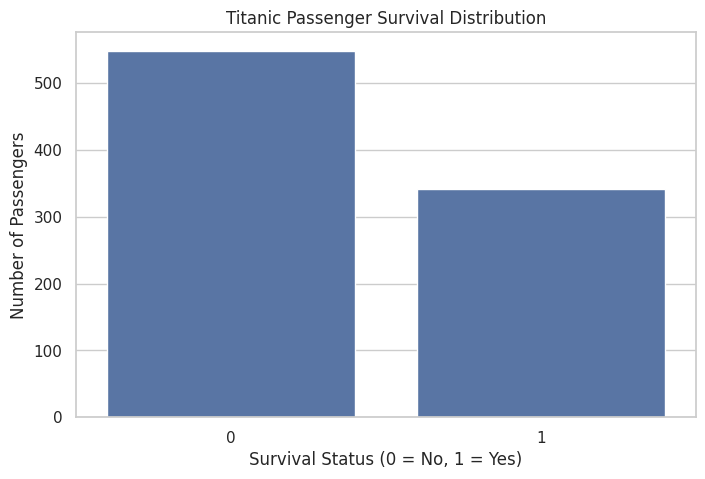


SURVIVAL RATE BY GENDER
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

SURVIVAL RATE BY PASSENGER CLASS
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


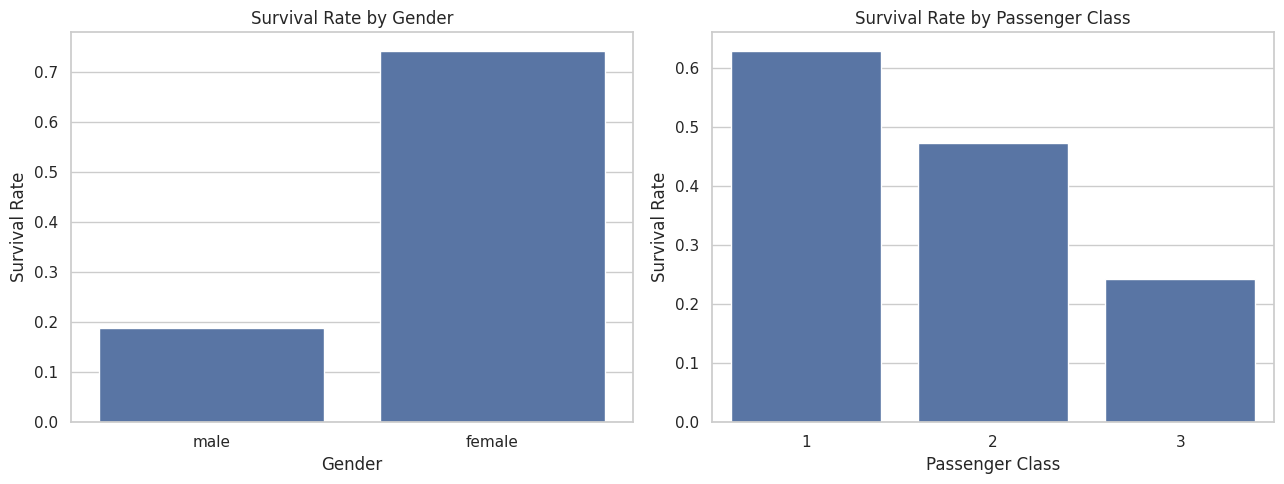

In [25]:

# ============================================
# 16.3 PASSENGER SURVIVAL DISTRIBUTION
# ============================================

# Calculate survival counts and percentages
survival_counts = train['Survived'].value_counts().sort_index()

survival_percentages = (
    train['Survived'].value_counts(normalize=True).sort_index() * 100
)

print("PASSENGER SURVIVAL DISTRIBUTION")
print("=" * 40)

print("\nSurvival Counts:")
print(survival_counts.rename({
    0: 'Did Not Survive',
    1: 'Survived'
}))

print("\nSurvival Percentages:")
print(survival_percentages.rename({
    0: 'Did Not Survive',
    1: 'Survived'
}).round(2))

# Visualize survival distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x='Survived'
)

plt.title('Titanic Passenger Survival Distribution')
plt.xlabel('Survival Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

# Analyze survival by gender
gender_survival = train.groupby('Sex')['Survived'].mean() * 100

print("\nSURVIVAL RATE BY GENDER")
print("=" * 40)
print(gender_survival.round(2))

# Analyze survival by passenger class
class_survival = train.groupby('Pclass')['Survived'].mean() * 100

print("\nSURVIVAL RATE BY PASSENGER CLASS")
print("=" * 40)
print(class_survival.round(2))

# Visualize survival patterns
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=train,
    x='Sex',
    y='Survived',
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Survival Rate by Gender')
axes[0].set_ylabel('Survival Rate')
axes[0].set_xlabel('Gender')

sns.barplot(
    data=train,
    x='Pclass',
    y='Survived',
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title('Survival Rate by Passenger Class')
axes[1].set_ylabel('Survival Rate')
axes[1].set_xlabel('Passenger Class')

plt.tight_layout()
plt.show()



# 17.Exploratory Data Analysis (EDA) — Key Findings

## a. Dataset Overview
The training dataset contains 891 passenger records and 12 columns, including the target variable `Survived`.

The dataset contains numerical and categorical variables that describe passenger demographics, ticket information, family relationships, and travel details.

## b. Missing Values Analysis
The missing-value analysis identified three columns with incomplete records:

- **Cabin:** 687 missing values (77.10%).
- **Age:** 177 missing values (19.87%).
- **Embarked:** 2 missing values (0.22%).

The Cabin feature has a substantial proportion of missing values. Age also requires appropriate imputation, while the few missing Embarked values can be handled using the most frequent category.

## c. Passenger Survival Distribution
The target variable contains the following distribution:

- Did Not Survive: 549 passengers (61.62%).
- Survived: 342 passengers (38.38%).

This indicates that most passengers in the training dataset did not survive.

The moderate class imbalance should be considered during model training and evaluation.

## d. Survival Rate by Gender
The analysis reveals a substantial difference in survival rates between genders:

- Female passengers: 74.20% survival rate.
- Male passengers: 18.89% survival rate.

Female passengers had considerably higher survival rates than male passengers. Gender therefore appears to be an important predictive feature.

## e. Survival Rate by Passenger Class
Survival rates varied considerably across passenger classes:

- First Class: 62.96%.
- Second Class: 47.28%.
- Third Class: 24.24%.

Passengers travelling in first class had the highest survival rate, while third-class passengers had the lowest.

This suggests that passenger class may be an important predictor of survival.

## f. Overall EDA Conclusion
The exploratory analysis reveals several potentially influential survival factors, particularly gender and passenger class.

Missing values, categorical variables, and differences in feature distributions must be addressed before model development.

These findings will guide feature engineering, preprocessing, model selection, and performance evaluation.


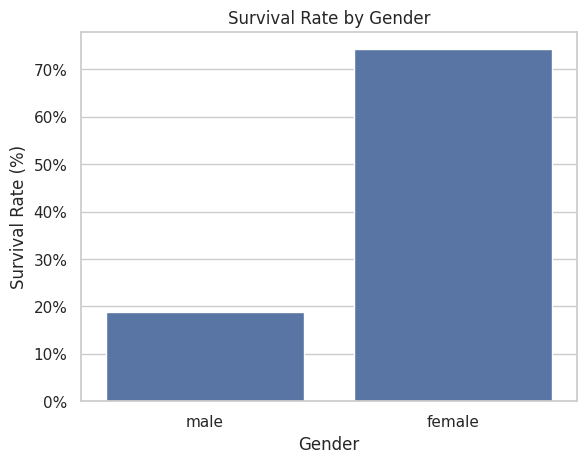

In [26]:
sns.barplot(
    data=train,
    x='Sex',
    y='Survived',
    errorbar=None
)

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate (%)')
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%')
)

plt.show()


# 18. Feature Engineering: Extracting Passenger Titles

Passenger names contain additional information that may help predict survival.

For example:
- Mr.
- Mrs.
- Miss.
- Master.
- Dr.
- Rev.

These titles may represent differences in age, gender, social status, and passenger characteristics.

We will extract titles from the `Name` column in both the training and test datasets.

The extracted title will become a new categorical feature called `Title`.

We will then examine the distribution of titles and identify less frequent categories that may need grouping.


Passenger Title Distribution

Training Dataset:
Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

Test Dataset:
Title
Mr        240
Miss       78
Mrs        72
Master     21
Col         2
Rev         2
Ms          1
Dr          1
Dona        1
Name: count, dtype: int64


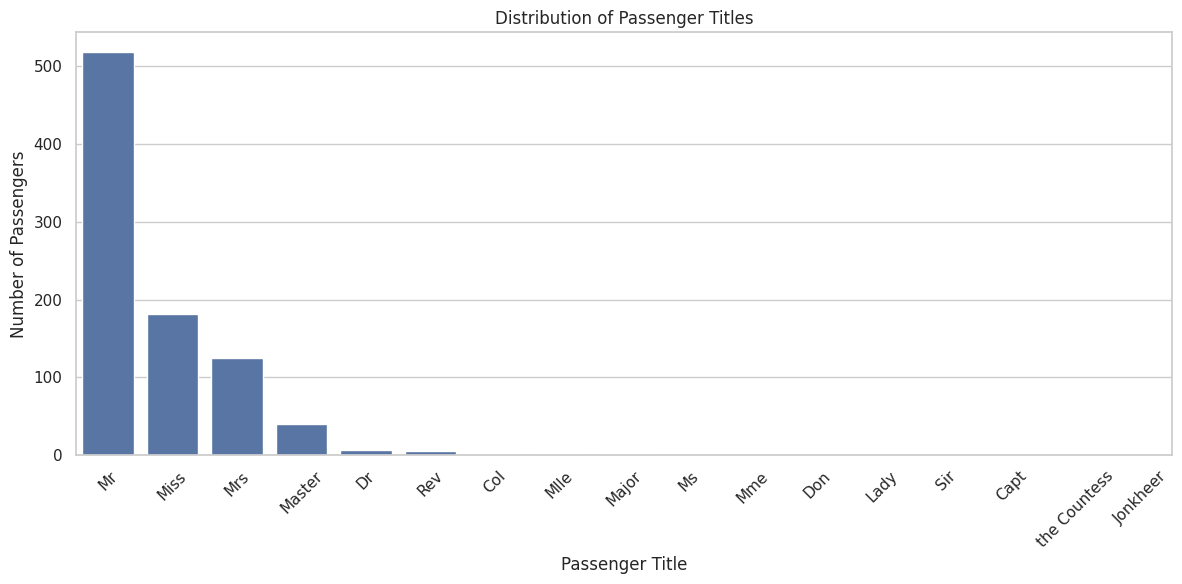

In [27]:

# Extract passenger titles from names
train['Title'] = train['Name'].str.extract(r',\s*([^.]*)\.')

test['Title'] = test['Name'].str.extract(r',\s*([^.]*)\.')

# Display title distributions
print("Passenger Title Distribution")
print("=" * 40)

print("\nTraining Dataset:")
print(train['Title'].value_counts())

print("\nTest Dataset:")
print(test['Title'].value_counts())

# Visualize title distribution
plt.figure(figsize=(12, 6))

sns.countplot(
    data=train,
    x='Title',
    order=train['Title'].value_counts().index
)

plt.title('Distribution of Passenger Titles')
plt.xlabel('Passenger Title')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



# 19. Feature Engineering: Grouping Rare Passenger Titles

The title extraction process identified several common and uncommon passenger titles.

To reduce categorical complexity and improve model generalization, we will retain the four most frequent titles:

- Mr
- Miss
- Mrs
- Master

All other titles will be grouped into a single category called `Rare`.

This transformation will be applied consistently to both training and test datasets to maintain feature compatibility.


Updated Training Title Distribution:
Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

Updated Test Title Distribution:
Title
Mr        240
Miss       78
Mrs        72
Master     21
Rare        7
Name: count, dtype: int64


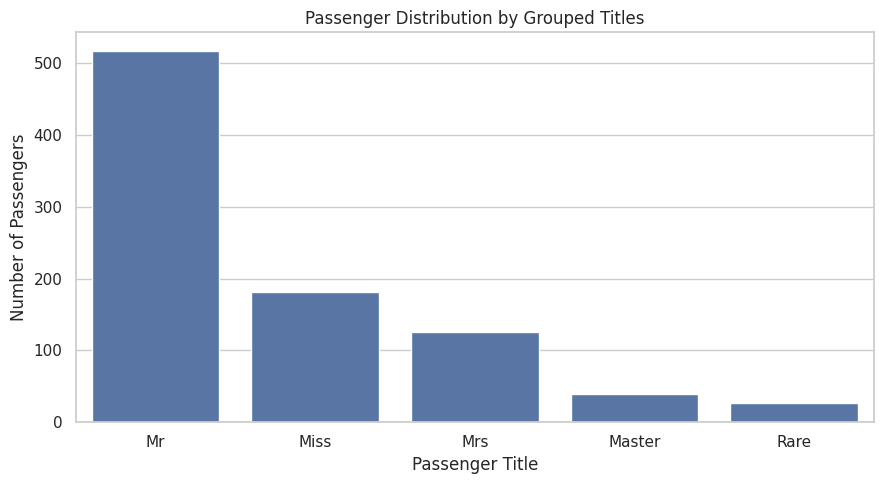

In [28]:

# Define the four most frequent titles
common_titles = ['Mr', 'Miss', 'Mrs', 'Master']

# Group uncommon titles into Rare
train['Title'] = train['Title'].apply(
    lambda x: x if x in common_titles else 'Rare'
)

test['Title'] = test['Title'].apply(
    lambda x: x if x in common_titles else 'Rare'
)

# Display updated title distributions
print("Updated Training Title Distribution:")
print(train['Title'].value_counts())

print("\nUpdated Test Title Distribution:")
print(test['Title'].value_counts())

# Visualize grouped titles
plt.figure(figsize=(9, 5))

sns.countplot(
    data=train,
    x='Title',
    order=['Mr', 'Miss', 'Mrs', 'Master', 'Rare']
)

plt.title('Passenger Distribution by Grouped Titles')
plt.xlabel('Passenger Title')
plt.ylabel('Number of Passengers')
plt.tight_layout()
plt.show()



# 20. Survival Analysis by Passenger Title

We will investigate the relationship between passenger titles and survival rates.

By calculating the percentage of passengers who survived within each title category, we can determine whether title information provides meaningful predictive signals.

This analysis will help evaluate the usefulness of the engineered `Title` feature before incorporating it into our machine learning models.


SURVIVAL RATE BY PASSENGER TITLE


,Total Passengers,Survivors,Survival Rate
Title,,,
Mrs,125,99,79.20
Miss,182,127,69.78
Master,40,23,57.50
Rare,27,12,44.44
Mr,517,81,15.67


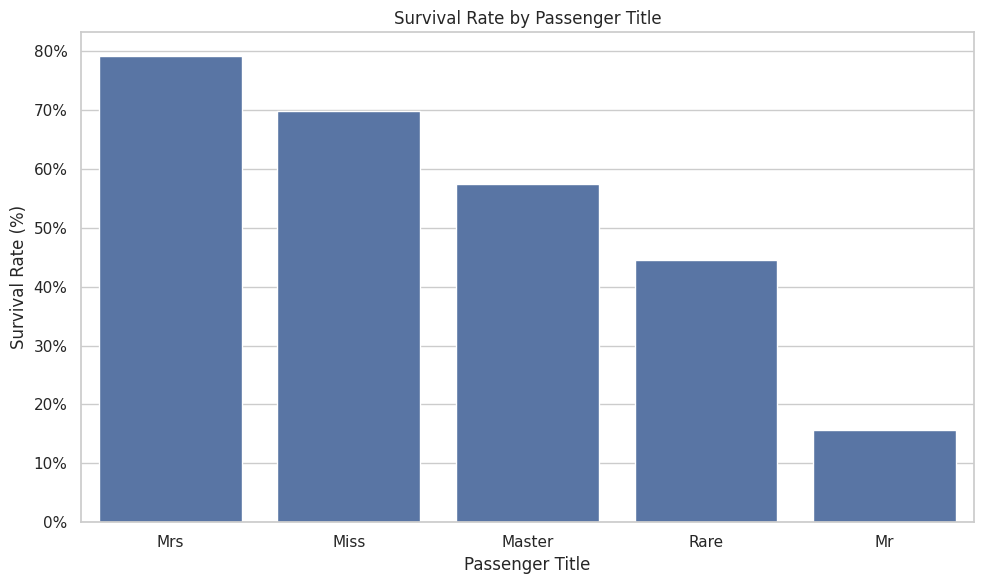

In [29]:

# Calculate survival rate by passenger title
title_survival = (
    train.groupby('Title')['Survived']
    .agg(['count', 'sum', 'mean'])
)

title_survival.columns = [
    'Total Passengers',
    'Survivors',
    'Survival Rate'
]

title_survival['Survival Rate'] *= 100

# Sort by survival rate
title_survival = title_survival.sort_values(
    by='Survival Rate',
    ascending=False
)

print("SURVIVAL RATE BY PASSENGER TITLE")
print("=" * 45)

display(title_survival.round(2))

# Visualize survival rates
plt.figure(figsize=(10, 6))

sns.barplot(
    data=train,
    x='Title',
    y='Survived',
    order=title_survival.index,
    errorbar=None
)

plt.title('Survival Rate by Passenger Title')
plt.xlabel('Passenger Title')
plt.ylabel('Survival Rate (%)')

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%')
)

plt.tight_layout()
plt.show()


## a. FEATURE ENGINEERING – PASSENGER TITLE

Passenger names contain titles such as Mr, Mrs, Miss, and Master, which provide useful demographic information.

In this section, we incorporate the extracted and grouped passenger titles into our machine learning dataset.

The following steps will:

1. Include the Title feature in the training and testing datasets.
2. Treat Title as a categorical variable.
3. Apply appropriate preprocessing through one-hot encoding.
4. Prepare the enhanced feature set for model training.

The objective is to capture additional patterns that may improve the model's ability to predict passenger survival.

In [30]:
# Verify that Title exists in both datasets
print("Training Title feature:", 'Title' in train.columns)
print("Testing Title feature:", 'Title' in test.columns)

# Define numerical features
numerical_features = [
    'Pclass',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'FamilySize',
    'IsAlone'
]

# Define categorical features
categorical_features = [
    'Sex',
    'Embarked',
    'Title'
]

# Combine all selected features
features = numerical_features + categorical_features

# Separate features and target
X = train[features].copy()
y = train['Survived'].copy()

# Prepare test features
X_test = test[features].copy()

print("\nFeature engineering completed!")
print("Training dataset:", X.shape)
print("Testing dataset:", X_test.shape)

print("\nSelected features:")
print(features)

Training Title feature: True
Testing Title feature: True


KeyError: "['FamilySize', 'IsAlone'] not in index"

In [31]:
# Create FamilySize feature in training dataset
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1

# Create IsAlone feature in training dataset
train['IsAlone'] = (train['FamilySize'] == 1).astype(int)

# Create FamilySize feature in testing dataset
test['FamilySize'] = test['SibSp'] + test['Parch'] + 1

# Create IsAlone feature in testing dataset
test['IsAlone'] = (test['FamilySize'] == 1).astype(int)

# Verify new features
print("Training features:")
display(train[['FamilySize', 'IsAlone', 'Title']].head())

print("\nTesting features:")
display(test[['FamilySize', 'IsAlone', 'Title']].head())

print("\nFeature creation completed successfully!")

Training features:


,FamilySize,IsAlone,Title
0,2,0,Mr
1,2,0,Mrs
2,1,1,Miss
3,2,0,Mrs
4,1,1,Mr



Testing features:


,FamilySize,IsAlone,Title
0,1,1,Mr
1,2,0,Mrs
2,1,1,Mr
3,1,1,Mr
4,3,0,Mrs



Feature creation completed successfully!


In [32]:
# Define numerical features
numerical_features = [
    'Pclass',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'FamilySize',
    'IsAlone'
]

# Define categorical features
categorical_features = [
    'Sex',
    'Embarked',
    'Title'
]

# Combine selected features
features = numerical_features + categorical_features

# Separate training features and target
X = train[features].copy()
y = train['Survived'].copy()

# Prepare testing features
X_test = test[features].copy()

# Display dataset information
print("FEATURE SELECTION COMPLETED")
print("============================")
print("Training dataset:", X.shape)
print("Testing dataset:", X_test.shape)
print("Number of features:", len(features))

print("\nSelected features:")
print(features)

FEATURE SELECTION COMPLETED
Training dataset: (891, 10)
Testing dataset: (418, 10)
Number of features: 10

Selected features:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Sex', 'Embarked', 'Title']


## b. DATA PREPROCESSING AND PIPELINE CONSTRUCTION

Before training our machine learning model, we need to prepare the dataset for optimal performance.

This stage involves:

1. Handling missing numerical values using median imputation.
2. Handling missing categorical values using the most frequent value.
3. Encoding categorical variables using One-Hot Encoding.
4. Combining preprocessing and model training into a single Scikit-learn pipeline.

Using a pipeline ensures consistent preprocessing during training, cross-validation, and prediction while preventing data leakage between training and validation datasets.

In [33]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Validate the preprocessing pipeline

In [34]:
# Fit preprocessing on training data
X_processed = preprocessor.fit_transform(X)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("PREPROCESSING RESULTS")
print("=====================")

print("Training shape:", X_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("Training missing values:",
      pd.isna(X_processed).sum())

print("Test missing values:",
      pd.isna(X_test_processed).sum())

PREPROCESSING RESULTS
Training shape: (891, 17)
Testing shape: (418, 17)
Training missing values: 0
Test missing values: 0


## c. RANDOM FOREST MODEL DEVELOPMENT

We will now develop a Random Forest classification model to predict passenger survival.

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve predictive performance and reduce overfitting.

Our approach will involve:

1. Splitting the dataset into training and validation subsets.
2. Training a Random Forest classifier.
3. Evaluating performance using accuracy, precision, recall, F1-score, and confusion matrix.
4. Applying stratified cross-validation to assess model stability.

We will use reproducible random states to ensure consistent experimental results.

In [35]:
from sklearn.model_selection import train_test_split

# Split the original training data
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("DATA SPLIT COMPLETED")
print("====================")

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

print("\nTraining survival distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation survival distribution:")
print(y_val.value_counts(normalize=True) * 100)

DATA SPLIT COMPLETED
Training samples: 712
Validation samples: 179

Training survival distribution:
Survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64

Validation survival distribution:
Survived
0    61.452514
1    38.547486
Name: proportion, dtype: float64


## d. RANDOM FOREST CLASSIFICATION

We will implement a Random Forest classifier integrated with the preprocessing pipeline.

The model will use an ensemble of 300 decision trees, with controlled tree depth and minimum sample requirements to manage overfitting.

The complete pipeline ensures that preprocessing is fitted independently within the training process and consistently applied during validation.

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create complete machine learning pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=7,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features='sqrt',
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


Train and evaluate the model

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Train the complete pipeline
rf_pipeline.fit(X_train, y_train)

# Generate validation predictions
y_pred = rf_pipeline.predict(X_val)

# Calculate evaluation metrics
accuracy = accuracy_score(y_val, y_pred)
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)

# Display results
print("RANDOM FOREST MODEL EVALUATION")
print("================================")

print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

RANDOM FOREST MODEL EVALUATION
Accuracy:  0.8324 (83.24%)
Precision: 0.7826
Recall:    0.7826
F1-Score:  0.7826

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86       110
           1       0.78      0.78      0.78        69

    accuracy                           0.83       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179


Confusion Matrix:
[[95 15]
 [15 54]]


## e. STRATIFIED CROSS-VALIDATION

To evaluate the reliability and generalization ability of our Random Forest model, we will perform stratified K-fold cross-validation.

Instead of relying on a single training-validation split, the dataset will be divided into five folds.

Each fold will serve as a validation set once, while the remaining four folds are used for training.

Stratification ensures that each fold maintains approximately the same survival class distribution as the original dataset.

We will evaluate the model using:

- Accuracy
- Precision
- Recall
- F1-score

The mean and standard deviation of the cross-validation scores will help us assess model stability.

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np

# Initialize stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

# Perform cross-validation
cv_results = cross_validate(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display individual fold results
print("STRATIFIED CROSS-VALIDATION RESULTS")
print("===================================")

for metric in scoring:
    scores = cv_results[f'test_{metric}']

    print(f"\n{metric.upper()}:")
    print("Fold scores:", np.round(scores, 4))
    print(f"Mean: {scores.mean():.4f}")
    print(f"Standard deviation: {scores.std():.4f}")

# Overall accuracy
cv_accuracy = cv_results['test_accuracy']

print("\nOVERALL CROSS-VALIDATION ACCURACY")
print("=================================")
print(f"Mean accuracy: {cv_accuracy.mean() * 100:.2f}%")
print(f"Standard deviation: {cv_accuracy.std() * 100:.2f}%")

STRATIFIED CROSS-VALIDATION RESULTS

ACCURACY:
Fold scores: [0.8212 0.8202 0.8371 0.8315 0.8483]
Mean: 0.8317
Standard deviation: 0.0105

PRECISION:
Fold scores: [0.7761 0.75   0.8421 0.8065 0.7763]
Mean: 0.7902
Standard deviation: 0.0315

RECALL:
Fold scores: [0.7536 0.7941 0.7059 0.7353 0.8551]
Mean: 0.7688
Standard deviation: 0.0518

F1:
Fold scores: [0.7647 0.7714 0.768  0.7692 0.8138]
Mean: 0.7774
Standard deviation: 0.0183

OVERALL CROSS-VALIDATION ACCURACY
Mean accuracy: 83.17%
Standard deviation: 1.05%


## f. Hyperparameter Optimization Using RandomizedSearchCV

We will optimize the Random Forest classifier using randomized hyperparameter search with stratified five-fold cross-validation.

The objective is to identify a configuration that improves predictive accuracy while maintaining model generalization and reducing overfitting.

In [39]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

# Define hyperparameter search space
param_distributions = {
    'classifier__n_estimators': randint(150, 601),
    'classifier__max_depth': [None, 4, 6, 8, 10, 12, 15],
    'classifier__min_samples_split': randint(2, 16),
    'classifier__min_samples_leaf': randint(1, 8),
    'classifier__max_features': ['sqrt', 'log2', 0.7, 1.0],
    'classifier__class_weight': [
        None, 'balanced', 'balanced_subsample'
    ]
}

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize randomized search
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=50,
    scoring='accuracy',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter optimization
random_search.fit(X, y)

# Display optimization results
print("HYPERPARAMETER OPTIMIZATION RESULTS")
print("=" * 45)

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(f"{random_search.best_score_ * 100:.2f}%")


Fitting 5 folds for each of 50 candidates, totalling 250 fits
HYPERPARAMETER OPTIMIZATION RESULTS

Best Parameters:
{'classifier__class_weight': None, 'classifier__max_depth': 12, 'classifier__max_features': 1.0, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 14, 'classifier__n_estimators': 487}

Best Cross-Validation Accuracy:
84.96%


# 21. Retrieve the optimized pipeline
best_model = random_search.best_estimator_

## a. Extract the fitted preprocessing and classifier steps
preprocessor = best_model.named_steps['preprocessor']
classifier = best_model.named_steps['classifier']

## b. Retrieve transformed feature names
feature_names = preprocessor.get_feature_names_out()

## c. Extract feature importance scores
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': classifier.feature_importances_
})

## d. Rank features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

## e. Display feature importance
print("FEATURE IMPORTANCE RANKING")
print("=" * 40)
display(importance_df)

## f. Visualize feature importance
plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


FEATURE IMPORTANCE RANKING


,Feature,Importance
0,cat__Title_Mr,0.299988
1,num__Fare,0.169305
2,num__Pclass,0.110082
3,num__Age,0.110082
4,cat__Sex_male,0.086961
5,cat__Sex_female,0.086272
6,num__FamilySize,0.064659
7,cat__Title_Rare,0.020153
8,num__SibSp,0.013729
9,cat__Embarked_S,0.011346


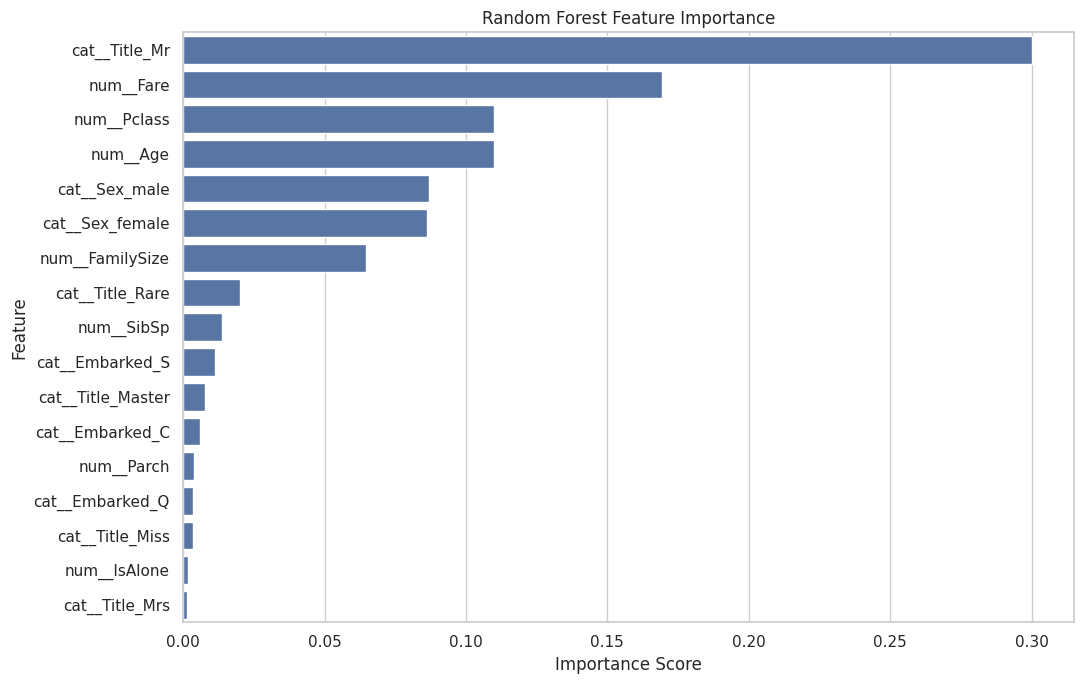

In [40]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve the optimized pipeline
best_model = random_search.best_estimator_

# Extract the fitted preprocessing and classifier steps
preprocessor = best_model.named_steps['preprocessor']
classifier = best_model.named_steps['classifier']

# Retrieve transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance scores
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': classifier.feature_importances_
})

# Rank features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Display feature importance
print("FEATURE IMPORTANCE RANKING")
print("=" * 40)
display(importance_df)

# Visualize feature importance
plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


# 22. Permutation Feature Importance Analysis

Permutation importance evaluates the contribution of individual features by measuring the reduction in model performance when each feature is randomly shuffled.

Unlike impurity-based feature importance, this approach measures the impact of feature disruption on predictive performance using unseen validation data.

This analysis will help identify the most useful predictors and guide further feature engineering.

PERMUTATION FEATURE IMPORTANCE


,Feature,Importance,Std
0,Title,0.206518,0.030067
1,Pclass,0.097579,0.016430
2,Fare,0.047858,0.011511
3,Age,0.043203,0.011260
4,Sex,0.028305,0.017305
5,FamilySize,0.025885,0.009178
6,Embarked,0.009125,0.006031
7,SibSp,0.007076,0.004770
8,Parch,0.001676,0.002560
9,IsAlone,0.000000,0.000000


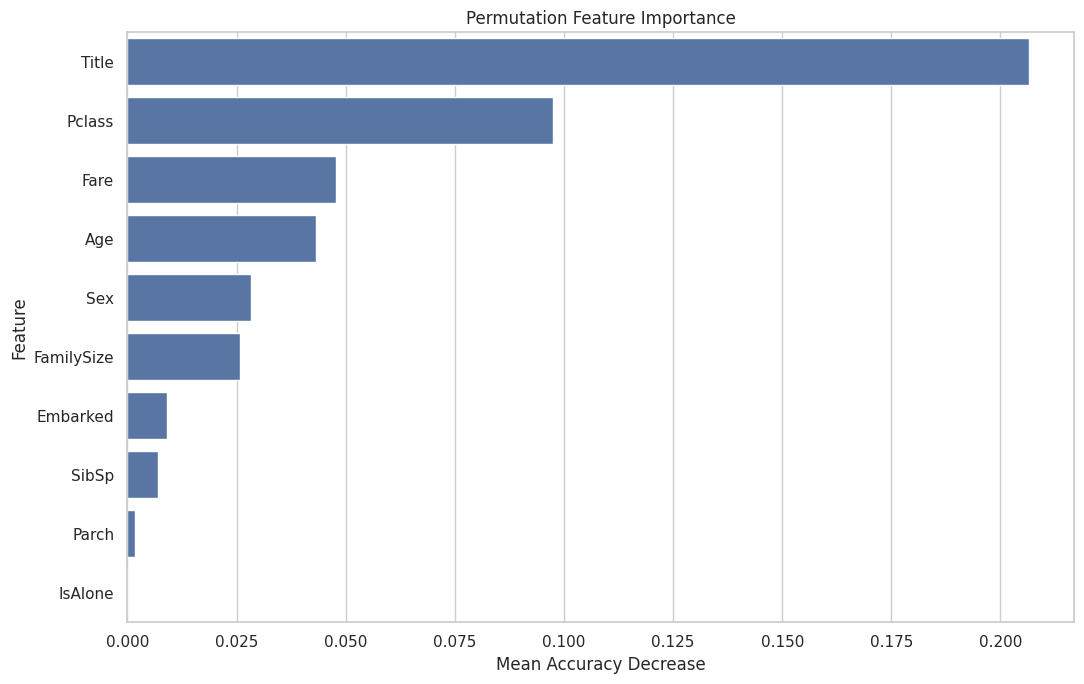

In [41]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate permutation importance on validation data
perm_results = permutation_importance(
    best_model,
    X_val,
    y_val,
    n_repeats=30,
    random_state=42,
    scoring='accuracy',
    n_jobs=-1
)

# Create importance dataframe
perm_importance_df = pd.DataFrame({
    'Feature': X_val.columns,
    'Importance': perm_results.importances_mean,
    'Std': perm_results.importances_std
})

# Sort features by importance
perm_importance_df = perm_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("PERMUTATION FEATURE IMPORTANCE")
print("=" * 45)
display(perm_importance_df)

# Visualize results
plt.figure(figsize=(11, 7))

sns.barplot(
    data=perm_importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Permutation Feature Importance')
plt.xlabel('Mean Accuracy Decrease')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


# 23. Final Model Training and Kaggle Submission

The optimized Random Forest pipeline is retrained using the complete labeled training dataset to maximize the available learning information.

After training, the model will generate survival predictions for the unseen test dataset. These predictions will be formatted according to Kaggle's submission requirements.

In [42]:
# 23(a). Final Model Training on the Entire Training Dataset

# Train the optimized pipeline on all available training data
best_model.fit(X, y)

print("FINAL MODEL TRAINING COMPLETED")
print("=" * 45)
print("Training samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Model:", best_model.named_steps['classifier'])
print("Training completed successfully.")

FINAL MODEL TRAINING COMPLETED
Training samples: 891
Number of features: 10
Model: RandomForestClassifier(max_depth=12, max_features=1.0, min_samples_leaf=5,
                       min_samples_split=14, n_estimators=487, n_jobs=-1,
                       random_state=42)
Training completed successfully.


## b. Generating Predictions on the Test Dataset

The optimized Random Forest pipeline has been trained on the complete labeled training dataset.

In this step, the trained model will predict passenger survival outcomes for the unseen test dataset.

The fitted pipeline automatically applies the same preprocessing and feature transformations learned during training, ensuring consistency between the training and testing data.

The resulting predictions will be used to construct the Kaggle submission file.

In [50]:
# 23(b). Generate Predictions on the Test Dataset

# Generate survival predictions using the optimized model
test_predictions = best_model.predict(X_test)

# Display prediction summary
print("TEST DATASET PREDICTIONS")
print("=" * 45)

print("Number of test samples:", len(test_predictions))
print("Total predicted survivors:", (test_predictions == 1).sum())
print("Total predicted non-survivors:", (test_predictions == 0).sum())

print("\nPrediction distribution:")
print(pd.Series(test_predictions).value_counts())

print("\nPrediction generation completed successfully.")

TEST DATASET PREDICTIONS
Number of test samples: 418
Total predicted survivors: 151
Total predicted non-survivors: 267

Prediction distribution:
0    267
1    151
Name: count, dtype: int64

Prediction generation completed successfully.


## c. Preparing the Kaggle Submission DataFrame

Kaggle requires predictions to be submitted in a specific tabular format.

For the Titanic competition, the submission must contain two columns:

- **PassengerId:** The unique identifier of each passenger in the original test dataset.
- **Survived:** The model's predicted survival outcome (0 or 1).

The submission DataFrame will combine the original passenger identifiers with the predictions generated in the previous step.

In [51]:
# 23(c). Create the Submission DataFrame

submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': test_predictions
})

print("KAGGLE SUBMISSION PREVIEW")
print("=" * 45)

display(submission.head(10))

print("\nSubmission shape:", submission.shape)
print("Submission columns:", submission.columns.tolist())

KAGGLE SUBMISSION PREVIEW


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0



Submission shape: (418, 2)
Submission columns: ['PassengerId', 'Survived']


## d. Submission Data Validation

Before exporting the submission file, validation checks will be performed to ensure that the predictions satisfy Kaggle's submission requirements.

The checks will verify:

1. The submission contains the expected number of test records.
2. The required columns are present and correctly ordered.
3. Passenger identifiers contain no missing or duplicate values.
4. Survival predictions contain only valid binary values (0 and 1).
5. No missing values exist in the submission DataFrame.

These checks help prevent formatting and data integrity errors during submission.

In [52]:
# 23(d). Validate Submission Data

print("SUBMISSION VALIDATION RESULTS")
print("=" * 45)

# Check submission dimensions
print("Expected test samples:", len(test))
print("Actual submission samples:", len(submission))

# Check required columns
print("\nColumn validation:",
      submission.columns.tolist() == ['PassengerId', 'Survived'])

# Check missing values
print("Missing values:", submission.isnull().sum().sum())

# Check duplicate passenger IDs
print("Duplicate PassengerIds:",
      submission['PassengerId'].duplicated().sum())

# Check valid prediction values
print("Valid survival predictions:",
      submission['Survived'].isin([0, 1]).all())

# Final validation
assert len(submission) == len(test)
assert submission.columns.tolist() == ['PassengerId', 'Survived']
assert submission.isnull().sum().sum() == 0
assert submission['PassengerId'].is_unique
assert submission['Survived'].isin([0, 1]).all()

print("\nAll submission validation checks passed.")

SUBMISSION VALIDATION RESULTS
Expected test samples: 418
Actual submission samples: 418

Column validation: True
Missing values: 0
Duplicate PassengerIds: 0
Valid survival predictions: True

All submission validation checks passed.


## e. Exporting the Final Kaggle Submission File

After successful validation, the submission DataFrame will be exported as a CSV file.

The file will be saved in Kaggle's working directory using the filename `submission.csv`.

This file will contain the passenger identifiers and corresponding survival predictions in the exact format required by the Titanic competition.

The exported file will be ready for upload to the Kaggle competition submission interface.

In [53]:
# 23(e). Export Final Submission File

submission.to_csv(
    '/kaggle/working/submission.csv',
    index=False
)

print("KAGGLE SUBMISSION EXPORT COMPLETED")
print("=" * 45)

print("File: submission.csv")
print("Location: /kaggle/working/submission.csv")
print("Total records:", len(submission))

print("\nExport completed successfully.")

KAGGLE SUBMISSION EXPORT COMPLETED
File: submission.csv
Location: /kaggle/working/submission.csv
Total records: 418

Export completed successfully.


## f. Verifying the Exported Submission File

The final step is to confirm that the CSV file was successfully created and that its contents retain the expected structure.

The exported file will be loaded back into a DataFrame to verify its dimensions, column names, and sample records.

This final verification establishes that the submission artifact is ready for Kaggle upload.

In [54]:
# 23(f). Verify Exported Submission

import os

submission_path = '/kaggle/working/submission.csv'

# Verify file existence
if os.path.exists(submission_path):

    # Load exported submission
    verified_submission = pd.read_csv(submission_path)

    print("FINAL SUBMISSION FILE VERIFIED")
    print("=" * 45)

    print("File exists:", True)
    print("File size:", round(os.path.getsize(submission_path) / 1024, 2), "KB")
    print("Dataset shape:", verified_submission.shape)
    print("Columns:", verified_submission.columns.tolist())

    print("\nFirst 10 submission records:")
    display(verified_submission.head(10))

    print("\nFinal submission is ready for Kaggle upload.")

else:
    print("Submission file was not found.")

FINAL SUBMISSION FILE VERIFIED
File exists: True
File size: 2.77 KB
Dataset shape: (418, 2)
Columns: ['PassengerId', 'Survived']

First 10 submission records:


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0



Final submission is ready for Kaggle upload.
